# County-level severity mix of VA disability compensation

**Data:** `data/raw/Disability.csv` — counts of disability compensation recipients per US county, split by
service-connected disability (SCD) rating band, age band and sex.

**Outcome studied:** the *high-rating share* of a county = recipients rated 70% or higher ÷ all recipients.

## Questions and hypotheses (written before the results were produced)

| | Question | Hypothesis |
|---|---|---|
| RQ1 | How much does the high-rating share differ between counties and states? | H1: county shares vary more than chance (binomial sampling noise) alone would produce |
| RQ2 | Is the high-rating share related to a county's age mix, female share and size? | H2: at least one of these is related to the share (two-sided, no direction assumed) |
| RQ3 | Can those four county features predict the share in a state the model has never seen? | H3: accuracy under state-grouped cross-validation is lower than under random cross-validation |

Fixed settings: seed 42; 5-fold cross-validation repeated 10 times; models used with fixed settings (no tuning);
2,000 bootstrap resamples of whole states for confidence intervals.

The dataset has no population or veteran counts, so **rates per resident or per veteran cannot be computed**.
Everything here is about the *composition* of recipients inside each county.

Each code cell below does one task. Run them in order.

## Part A — Setup

In [1]:
# Task 1: Import the libraries
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

In [2]:
# Task 2: Settings
DATA_FILE = Path("../data/raw/Disability.csv")
RESULTS = Path("../results")
RESULTS.mkdir(exist_ok=True)

SEED = 42
N_REPEATS = 10      # cross-validation repeats
N_FOLDS = 5         # folds per repeat
N_BOOT = 2000       # bootstrap resamples

In [3]:
# Task 3: Plot style used by every figure
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, AXIS, SURFACE = "#0b0b0b", "#52514e", "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": MUTED, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED, "axes.grid": True, "grid.color": GRID,
    "grid.linewidth": 0.8, "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "font.size": 10, "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
})

## Part B — Load and audit the data

In [4]:
# Task 4: Load the dataset as text (the raw file is never changed)
raw = pd.read_csv(DATA_FILE, dtype=str)
print("Rows and columns:", raw.shape)
raw.head()

Rows and columns: (3148, 14)


,FIPS code,State,County Name,Total: Disability Compensation Recipients,SCD rating: 0% to 20%,SCD rating: 30% to 40%,SCD rating: 50% to 60%,SCD rating: 70% to 90%,SCD rating: 100%,Age: 17-44,Age: 45-64,Age: 65 or older,Male,Female
0,01001,Alabama,Autauga,"2,949",420,250,346,924,"1,009",763,"1,278",908,"2,382",567
1,01003,Alabama,Baldwin,"7,650","1,590",780,909,"2,249","2,122","1,698","2,591","3,360","6,905",745
2,01005,Alabama,Barbour,646,102,48,75,207,214,108,240,298,564,82
3,01007,Alabama,Bibb,324,52,37,37,115,83,70,118,136,298,26
4,01009,Alabama,Blount,"1,088",182,132,146,342,286,288,326,474,"1,011",77


In [5]:
# Task 5: Give the columns short names
raw.columns = ["fips", "state", "county", "total", "r0_20", "r30_40", "r50_60", "r70_90", "r100",
               "age_17_44", "age_45_64", "age_65_plus", "male", "female"]
COUNTS = list(raw.columns[3:])
print(COUNTS)

['total', 'r0_20', 'r30_40', 'r50_60', 'r70_90', 'r100', 'age_17_44', 'age_45_64', 'age_65_plus', 'male', 'female']


In [6]:
# Task 6: Turn the count columns into numbers ("2,949" -> 2949, blank -> missing)
for c in COUNTS:
    raw[c] = pd.to_numeric(raw[c].str.replace(",", ""), errors="coerce")
raw[COUNTS].describe().loc[["count", "min", "50%", "max"]].T

,count,min,50%,max
total,3135.0,10.0,542.0,98159.0
r0_20,2984.0,10.0,130.0,15874.0
r30_40,2820.0,10.0,73.0,9364.0
r50_60,2833.0,10.0,80.0,10303.0
r70_90,3027.0,10.0,167.0,28075.0
r100,2987.0,10.0,144.0,38153.0
age_17_44,2966.0,10.0,130.0,37669.0
age_45_64,2969.0,10.0,183.0,37519.0
age_65_plus,3075.0,10.0,265.0,27556.0
male,2684.0,48.0,646.0,84275.0


Four rows are not counties (Puerto Rico as one total, other territories, foreign countries, unknown).

In [7]:
# Task 7: Show the rows that are not counties
NOT_COUNTY = ["72000", "88888", "00000", "Unknown"]
raw[raw.fips.isin(NOT_COUNTY)][["fips", "state", "total"]]

,fips,state,total
3144,72000,Puerto Rico,36399.0
3145,88888,US Territories (excluding Puerto Rico),7699.0
3146,00000,Other Foreign Countries,38497.0
3147,Unknown,Unknown,229.0


In [8]:
# Task 8: Keep only the county rows
df = raw[~raw.fips.isin(NOT_COUNTY)].copy()
print(f"{len(df):,} counties in {df.state.nunique()} states (50 states + DC)")

3,144 counties in 51 states (50 states + DC)


In [9]:
# Task 9: Check for duplicate counties
print("Duplicate FIPS codes:", df.fips.duplicated().sum())
print("Duplicate rows      :", df.duplicated().sum())

Duplicate FIPS codes: 0
Duplicate rows      : 0


**Blank cells.** The smallest number anywhere in the file is 10, so blanks are counts below 10 that the publisher
hid (small-cell suppression), not zeros.

In [10]:
# Task 10: Count the blank cells in each column
audit = pd.DataFrame({
    "blank_counties": df[COUNTS].isna().sum(),
    "blank_pct": (df[COUNTS].isna().mean() * 100).round(1),
    "smallest_value": df[COUNTS].min().astype(int),
})
audit.to_csv(RESULTS / "table_01_blank_cells.csv")
audit

,blank_counties,blank_pct,smallest_value
total,13,0.4,10
r0_20,164,5.2,10
r30_40,327,10.4,10
r50_60,314,10.0,10
r70_90,121,3.8,10
r100,161,5.1,10
age_17_44,182,5.8,10
age_45_64,179,5.7,10
age_65_plus,73,2.3,10
male,464,14.8,48


In [11]:
# Task 11: Check that male and female are always blank together
print("Male and female blank together:", (df.male.isna() == df.female.isna()).all())

Male and female blank together: True


In [12]:
# Task 12: Check that the parts add up to the total where nothing is hidden
full = df.dropna(subset=COUNTS)
checks = pd.Series({
    "rating bands sum to total": (full[["r0_20", "r30_40", "r50_60", "r70_90", "r100"]].sum(axis=1) == full.total).mean(),
    "age bands sum to total": (full[["age_17_44", "age_45_64", "age_65_plus"]].sum(axis=1) == full.total).mean(),
    "male + female = total": (full[["male", "female"]].sum(axis=1) == full.total).mean(),
})
print(f"Counties with no blank cell: {len(full):,}")
(checks * 100).round(1).rename("% of those counties")

Counties with no blank cell: 2,649


rating bands sum to total    100.0
age bands sum to total        98.9
male + female = total         81.8
Name: % of those counties, dtype: float64

## Part C — Build the analysis table

In [13]:
# Task 13: Create the two outcomes
df["high_share"] = (df.r70_90 + df.r100) / df.total      # main outcome: rated 70% or higher
df["full_share"] = df.r100 / df.total                    # second outcome: rated 100%
df[["high_share", "full_share"]].describe().loc[["count", "mean", "min", "max"]].round(3)

,high_share,full_share
count,2961.000,2983.000
mean,0.545,0.254
min,0.242,0.076
max,0.840,0.571


The other rating bands are **not** used as features: the five bands add up to 100%, so they would give the
answer away. The 45–64 age share is left out for the same reason (the three age shares add up to 100%).

In [14]:
# Task 14: Create the four features
df["young_share"] = df.age_17_44 / df.total
df["older_share"] = df.age_65_plus / df.total
df["female_share"] = df.female / df.total
df["log_total"] = np.log10(df.total)

FEATURES = ["young_share", "older_share", "female_share", "log_total"]
LABELS = {"young_share": "Share aged 17–44", "older_share": "Share aged 65 or older",
          "female_share": "Share female", "log_total": "County size (log10 recipients)"}
df[FEATURES].describe().loc[["count", "mean", "min", "max"]].round(3)

,young_share,older_share,female_share,log_total
count,2962.000,3071.000,2680.000,3131.000
mean,0.235,0.460,0.099,2.780
min,0.066,0.129,0.027,1.000
max,0.520,0.776,0.266,4.992


In [15]:
# Task 15: Select the main sample (counties with the outcome and all four features)
main = df.dropna(subset=["high_share"] + FEATURES).reset_index(drop=True)
print(f"Main sample: {len(main):,} of {len(df):,} counties "
      f"({main.total.sum() / df.total.sum():.1%} of all county recipients)")

Main sample: 2,674 of 3,144 counties (99.4% of all county recipients)


In [16]:
# Task 16: Compare the counties kept with the counties left out
df["in_main"] = df.fips.isin(main.fips)
selection = df.groupby("in_main").total.describe()[["count", "min", "50%", "max"]]
selection.index = ["left out", "main sample"]
selection.to_csv(RESULTS / "table_02_sample_selection.csv")
selection

,count,min,50%,max
left out,457.0,10.0,67.0,285.0
main sample,2674.0,62.0,710.5,98159.0


## Part D — RQ1: how much does the high-rating share vary?

In [17]:
# Task 17: Pooled high-rating share of all counties
national = (main.r70_90.sum() + main.r100.sum()) / main.total.sum()
print(f"Pooled share rated 70%+ (main sample): {national:.1%}")

Pooled share rated 70%+ (main sample): 58.6%


In [18]:
# Task 18: Spread of the county shares
q = main.high_share.quantile([0.05, 0.25, 0.5, 0.75, 0.95])
(q * 100).round(1).rename("high-rating share (%)")

0.05    39.5
0.25    50.0
0.50    55.8
0.75    60.5
0.95    66.2
Name: high-rating share (%), dtype: float64

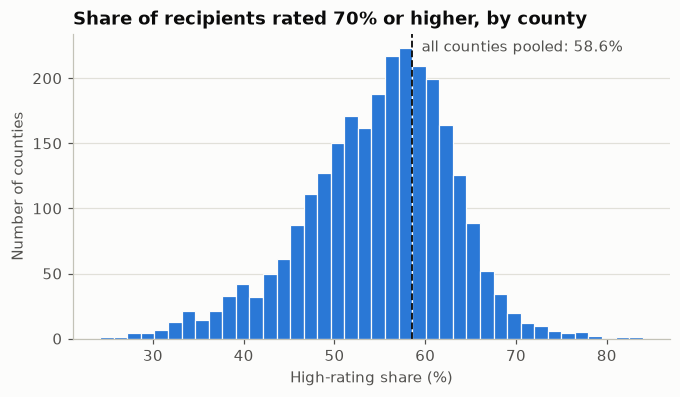

In [19]:
# Task 19: Figure — distribution of the county shares
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.hist(main.high_share * 100, bins=40, color=BLUE, edgecolor=SURFACE, linewidth=0.8)
ax.axvline(national * 100, color=INK, linewidth=1.2, linestyle="--")
ax.annotate(f"all counties pooled: {national:.1%}", (national * 100, ax.get_ylim()[1]),
            xytext=(6, -4), textcoords="offset points", va="top", color=MUTED)
ax.set(title="Share of recipients rated 70% or higher, by county",
       xlabel="High-rating share (%)", ylabel="Number of counties")
ax.grid(axis="x", visible=False)
fig.savefig(RESULTS / "fig_01_county_distribution.png")
plt.show()

**Is that spread more than chance?** A county of 100 recipients would show a noisy share even if every county had
the same true share. The expected chance variance is `p(1−p)/n` per county; the rest is real between-county difference.

In [20]:
# Task 20: Observed spread against the spread expected from chance
observed_var = main.high_share.var()
chance_var = (national * (1 - national) / main.total).mean()
noise_ceiling = 1 - chance_var / observed_var
print(f"Observed SD of county shares     : {np.sqrt(observed_var) * 100:.2f} points")
print(f"SD expected from chance alone    : {np.sqrt(chance_var) * 100:.2f} points")
print(f"Share of variance that is not chance: {noise_ceiling:.1%}  (upper limit for any model's R²)")

Observed SD of county shares     : 8.10 points
SD expected from chance alone    : 2.23 points
Share of variance that is not chance: 92.4%  (upper limit for any model's R²)


In [21]:
# Task 21: Test H1 — chi-square test that all counties have the same share
chi2 = (((main.high_share - national) ** 2) / (national * (1 - national) / main.total)).sum()
p_value = stats.chi2.sf(chi2, len(main) - 1)
print(f"chi-square = {chi2:,.0f} on {len(main) - 1:,} df, p {'< 1e-300' if p_value == 0 else f'= {p_value:.3g}'}")

chi-square = 157,337 on 2,673 df, p < 1e-300


In [22]:
# Task 22: High-rating share of each state
by_state = main.groupby("state").agg(counties=("fips", "size"), recipients=("total", "sum"),
                                     high=("r70_90", "sum"), full=("r100", "sum"))
by_state["high_share"] = (by_state.high + by_state.full) / by_state.recipients
by_state = by_state.sort_values("high_share")
by_state[["counties", "recipients", "high_share"]].round(4).to_csv(RESULTS / "table_03_state_high_share.csv")
pd.concat([by_state.head(5), by_state.tail(5)])[["counties", "recipients", "high_share"]]

,counties,recipients,high_share
state,,,
Minnesota,73,105058.0,0.378534
Nebraska,42,45486.0,0.448731
Indiana,89,115775.0,0.454088
Iowa,88,51181.0,0.468103
South Dakota,30,21776.0,0.477314
Alabama,67,141973.0,0.633360
Georgia,150,273124.0,0.649785
Nevada,12,79982.0,0.650846
Texas,179,678548.0,0.653912


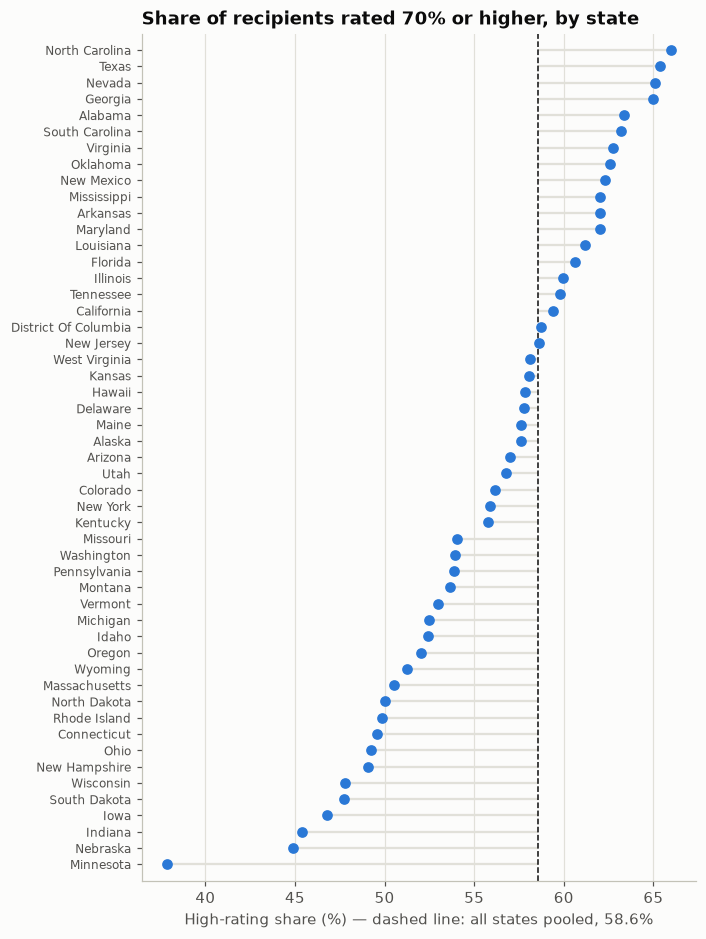

In [23]:
# Task 23: Figure — states ranked by high-rating share
fig, ax = plt.subplots(figsize=(6.5, 10))
y = np.arange(len(by_state))
ax.hlines(y, national * 100, by_state.high_share * 100, color=GRID, linewidth=1.5)
ax.scatter(by_state.high_share * 100, y, s=36, color=BLUE, zorder=3)
ax.axvline(national * 100, color=INK, linewidth=1, linestyle="--")
ax.set_yticks(y, by_state.index, fontsize=8)
ax.set_ylim(-1, len(by_state))
ax.set(title="Share of recipients rated 70% or higher, by state",
       xlabel=f"High-rating share (%) — dashed line: all states pooled, {national:.1%}")
ax.grid(axis="y", visible=False)
fig.savefig(RESULTS / "fig_02_state_ranking.png")
plt.show()

In [24]:
# Task 24: Share of the county variance that lies between states
state_mean = main.groupby("state").high_share.transform("mean")
grand_mean = main.high_share.mean()
between = ((state_mean - grand_mean) ** 2).sum() / ((main.high_share - grand_mean) ** 2).sum()
print(f"Share of county variance that lies between states: {between:.1%}")

Share of county variance that lies between states: 63.3%


## Part E — RQ2: what is the high-rating share related to?

Counties in the same state are not independent, so the confidence intervals resample **whole states**
(cluster bootstrap) instead of single counties.

In [25]:
# Task 25: Draw the bootstrap resamples of whole states
rng = np.random.default_rng(SEED)
states = main.state.unique()
rows_of = {s: np.flatnonzero(main.state.values == s) for s in states}
boot_rows = [np.concatenate([rows_of[s] for s in rng.choice(states, len(states))]) for _ in range(N_BOOT)]
print(f"{len(boot_rows):,} resamples of {len(states)} states")

2,000 resamples of 51 states


In [26]:
# Task 26: Spearman correlation of each feature with the high-rating share
def spearman(data, feature):
    return stats.spearmanr(data[feature], data["high_share"]).statistic

corr = pd.DataFrame({"spearman": [spearman(main, f) for f in FEATURES]}, index=[LABELS[f] for f in FEATURES])
corr.round(3)

,spearman
Share aged 17–44,0.176
Share aged 65 or older,-0.436
Share female,0.490
County size (log10 recipients),0.165


In [27]:
# Task 27: Test H2 — 95% confidence intervals for the correlations
for f in FEATURES:
    boots = [spearman(main.iloc[r], f) for r in boot_rows]
    corr.loc[LABELS[f], ["ci_low", "ci_high"]] = np.percentile(boots, [2.5, 97.5])
corr = corr.round(3)
corr.index.name = "feature"
corr.to_csv(RESULTS / "table_04_spearman.csv")
corr

,spearman,ci_low,ci_high
feature,,,
Share aged 17–44,0.176,0.038,0.298
Share aged 65 or older,-0.436,-0.538,-0.319
Share female,0.490,0.360,0.585
County size (log10 recipients),0.165,0.060,0.280


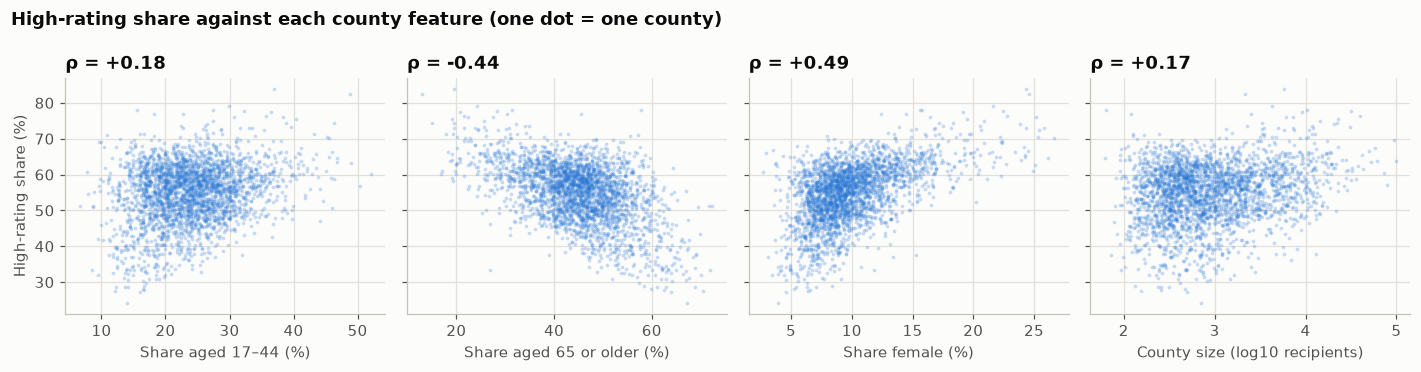

In [28]:
# Task 28: Figure — high-rating share against each feature
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
for ax, f in zip(axes, FEATURES):
    x = main[f] if f == "log_total" else main[f] * 100
    ax.scatter(x, main.high_share * 100, s=6, color=BLUE, alpha=0.25, linewidths=0)
    ax.set(xlabel=LABELS[f] + ("" if f == "log_total" else " (%)"),
           title=f"ρ = {corr.loc[LABELS[f], 'spearman']:+.2f}")
axes[0].set_ylabel("High-rating share (%)")
fig.suptitle("High-rating share against each county feature (one dot = one county)",
             x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
fig.savefig(RESULTS / "fig_03_feature_scatter.png")
plt.show()

**All four features together.** A linear model on standardised features: each coefficient is the change in the
high-rating share (percentage points) for a one-standard-deviation rise in that feature, holding the others fixed.

In [29]:
# Task 29: Linear model with all four features (standardised coefficients)
def std_coefs(data):
    X = (data[FEATURES] - data[FEATURES].mean()) / data[FEATURES].std()
    return LinearRegression().fit(X, data["high_share"] * 100).coef_

coefs = pd.DataFrame({"points_per_sd": std_coefs(main)}, index=[LABELS[f] for f in FEATURES])
coefs.round(2)

,points_per_sd
Share aged 17–44,-3.52
Share aged 65 or older,-5.70
Share female,1.96
County size (log10 recipients),0.03


In [30]:
# Task 30: 95% confidence intervals for the coefficients
boots = np.array([std_coefs(main.iloc[r]) for r in boot_rows])
coefs["ci_low"] = np.percentile(boots, 2.5, axis=0)
coefs["ci_high"] = np.percentile(boots, 97.5, axis=0)
coefs = coefs.round(2)
coefs["one_sd_equals"] = [f"{main[f].std() * 100:.1f} points" if f != "log_total" else f"×{10 ** main[f].std():.1f} recipients"
                          for f in FEATURES]
coefs.to_csv(RESULTS / "table_05_linear_coefficients.csv")
coefs

,points_per_sd,ci_low,ci_high,one_sd_equals
Share aged 17–44,-3.52,-4.85,-2.16,6.4 points
Share aged 65 or older,-5.70,-7.98,-3.30,8.9 points
Share female,1.96,0.98,3.11,3.4 points
County size (log10 recipients),0.03,-0.68,0.89,×3.5 recipients


## Part F — RQ3: prediction, and the effect of how the folds are made

Two ways of making the five folds:

- **Random folds** — counties are shuffled freely, so a test county usually has neighbours from the *same state* in training.
- **State-grouped folds** — all counties of a state go to the same fold, so every test county is in a state the model has never seen.

Four predictors are compared. *State average* uses no county feature at all: it predicts the average share of the
training counties in the same state (or the overall average when the state is unseen).

In [31]:
# Task 31: Prepare the arrays for modelling
X_all = main[FEATURES].values
y_all = main.high_share.values * 100          # in percentage points
state_all = main.state.values
print("X:", X_all.shape, "| y:", y_all.shape, "| states:", len(np.unique(state_all)))

X: (2674, 4) | y: (2674,) | states: 51


In [32]:
# Task 32: Define the random folds
def random_folds(repeat):
    splitter = KFold(N_FOLDS, shuffle=True, random_state=SEED + repeat)
    return [test for _, test in splitter.split(X_all)]

print("Test counties per fold:", [len(t) for t in random_folds(0)])

Test counties per fold: [535, 535, 535, 535, 534]


In [33]:
# Task 33: Define the state-grouped folds
def state_folds(repeat):
    order = np.random.default_rng(SEED + repeat).permutation(np.unique(state_all))
    return [np.flatnonzero(np.isin(state_all, chunk)) for chunk in np.array_split(order, N_FOLDS)]

print("Test counties per fold:", [len(t) for t in state_folds(0)])

Test counties per fold: [554, 429, 595, 552, 544]


In [34]:
# Task 34: Define the 'state average' predictor
def predict_state_average(train, test):
    means = pd.Series(y_all[train]).groupby(state_all[train]).mean()
    return pd.Series(state_all[test]).map(means).fillna(y_all[train].mean()).values

In [35]:
# Task 35: Define the four predictors
def from_sklearn(model):
    return lambda train, test: model.fit(X_all[train], y_all[train]).predict(X_all[test])

MODELS = {
    "Overall average (baseline)": from_sklearn(DummyRegressor()),
    "State average": predict_state_average,
    "Linear regression": from_sklearn(make_pipeline(StandardScaler(), LinearRegression())),
    "Gradient boosting": from_sklearn(HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                                                                    max_iter=200, random_state=SEED)),
}
print(list(MODELS))

['Overall average (baseline)', 'State average', 'Linear regression', 'Gradient boosting']


In [36]:
# Task 36: Define one cross-validation run (out-of-fold predictions for every county)
def out_of_fold(fit_predict, folds):
    everyone = np.arange(len(y_all))
    pred = np.empty(len(y_all))
    for test in folds:
        train = np.setdiff1d(everyone, test)
        pred[test] = fit_predict(train, test)
    return pred

In [37]:
# Task 37: Run every predictor under both fold designs
rows = []
for scheme, make_folds in [("Random folds", random_folds), ("State-grouped folds", state_folds)]:
    for repeat in range(N_REPEATS):
        folds = make_folds(repeat)
        for name, fit_predict in MODELS.items():
            pred = out_of_fold(fit_predict, folds)
            rows.append({"scheme": scheme, "model": name, "repeat": repeat,
                         "r2": r2_score(y_all, pred), "mae": mean_absolute_error(y_all, pred)})
cv = pd.DataFrame(rows)
cv.to_csv(RESULTS / "table_06_cv_all_repeats.csv", index=False)
print(f"{len(cv)} runs = 2 fold designs × {N_REPEATS} repeats × {len(MODELS)} predictors")

80 runs = 2 fold designs × 10 repeats × 4 predictors


In [38]:
# Task 38: Summarise the cross-validation scores
summary = cv.groupby(["model", "scheme"]).agg(r2=("r2", "mean"), r2_min=("r2", "min"), r2_max=("r2", "max"),
                                              mae=("mae", "mean")).round(3)
summary = summary.reindex(list(MODELS), level=0)
summary.to_csv(RESULTS / "table_07_cv_summary.csv")
summary

r2  r2_min  r2_max    mae
model                      scheme                                           
Overall average (baseline) Random folds        -0.001  -0.003  -0.000  6.373
                           State-grouped folds -0.047  -0.097  -0.012  6.531
State average              Random folds         0.618   0.616   0.620  3.848
                           State-grouped folds -0.047  -0.097  -0.012  6.531
Linear regression          Random folds         0.377   0.375   0.379  5.111
                           State-grouped folds  0.329   0.294   0.357  5.304
Gradient boosting          Random folds         0.405   0.402   0.409  4.998
                           State-grouped folds  0.339   0.308   0.363  5.249

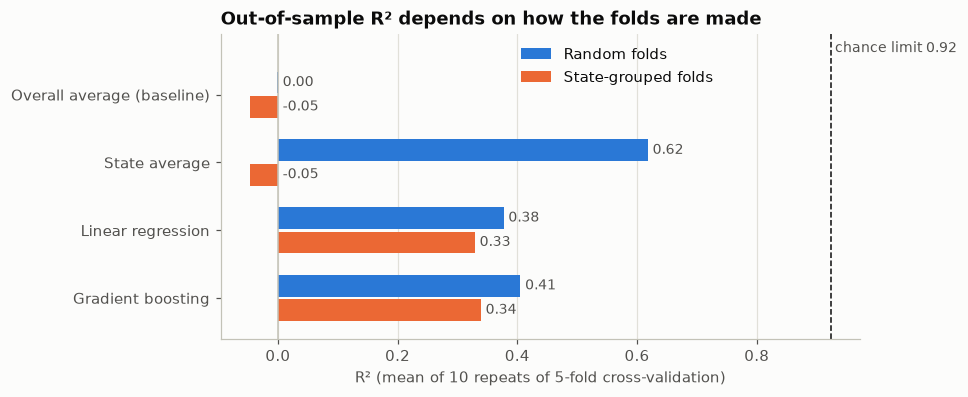

In [39]:
# Task 39: Figure — R² under random folds and state-grouped folds
fig, ax = plt.subplots(figsize=(7.5, 3.6))
names = list(MODELS)[::-1]
for k, (scheme, colour) in enumerate([("State-grouped folds", ORANGE), ("Random folds", BLUE)]):
    s = summary.xs(scheme, level="scheme").reindex(names)
    ypos = np.arange(len(names)) + (k - 0.5) * 0.36
    ax.barh(ypos, s.r2, height=0.32, color=colour, label=scheme)
    for yy, v in zip(ypos, s.r2):
        ax.text(max(v, 0) + 0.008, yy, f"{round(v, 2) + 0:.2f}", va="center", color=MUTED, fontsize=9)
ax.axvline(noise_ceiling, color=INK, linewidth=1, linestyle="--")
ax.text(noise_ceiling, len(names) - 0.42, f" chance limit {noise_ceiling:.2f}", color=MUTED, fontsize=9, va="bottom")
ax.axvline(0, color=AXIS, linewidth=1)
ax.set_yticks(np.arange(len(names)), names)
ax.set_ylim(-0.6, len(names) - 0.1)
ax.set(title="Out-of-sample R² depends on how the folds are made",
       xlabel=f"R² (mean of {N_REPEATS} repeats of {N_FOLDS}-fold cross-validation)")
ax.grid(axis="y", visible=False)
handles, legend_labels = ax.get_legend_handles_labels()
ax.legend(handles[::-1], legend_labels[::-1], frameon=False, loc="upper center", bbox_to_anchor=(0.62, 1.0))
fig.savefig(RESULTS / "fig_04_cv_random_vs_grouped.png")
plt.show()

In [40]:
# Task 40: Test H3 — is the grouped score lower than the random score in every repeat?
wide = cv.pivot_table(index=["model", "repeat"], columns="scheme", values="r2")
gap = (wide["Random folds"] - wide["State-grouped folds"]).groupby("model")
h3 = pd.DataFrame({"mean_r2_drop": gap.mean().round(3),
                   "repeats_with_drop": gap.apply(lambda g: int((g > 0).sum()))})
h3.reindex(list(MODELS))

,mean_r2_drop,repeats_with_drop
model,,
Overall average (baseline),0.046,10
State average,0.665,10
Linear regression,0.048,10
Gradient boosting,0.066,10


## Part G — Sensitivity checks

Each check repeats the state-grouped validation of the gradient-boosting model with one thing changed.

In [41]:
# Task 41: Define the state-grouped R² used by every check
def grouped_r2(data, features, target):
    X, y, st = data[features].values, data[target].values * 100, data.state.values
    model = HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05, max_iter=200, random_state=SEED)
    scores = []
    for repeat in range(N_REPEATS):
        order = np.random.default_rng(SEED + repeat).permutation(np.unique(st))
        pred = np.empty(len(y))
        for chunk in np.array_split(order, N_FOLDS):
            test = np.isin(st, chunk)
            pred[test] = model.fit(X[~test], y[~test]).predict(X[test])
        scores.append(r2_score(y, pred))
    return np.mean(scores)

sens = []

In [ ]:
# Task 42: Check 0 — main analysis (reference)
sens.append({"check": "Main analysis", "counties": len(main),
             "grouped_r2": grouped_r2(main, FEATURES, "high_share")})
sens[-1]

In [ ]:
# Task 43: Check 1 — without the female share, which keeps more small counties
no_sex = [f for f in FEATURES if f != "female_share"]
wider = df.dropna(subset=["high_share"] + no_sex)
sens.append({"check": "Without female share, larger sample", "counties": len(wider),
             "grouped_r2": grouped_r2(wider, no_sex, "high_share")})
sens[-1]

{'check': 'Without female share, larger sample',
 'counties': 2923,
 'grouped_r2': np.float64(0.29131419566363376)}

In [ ]:
# Task 44: Check 2 — only counties with 500 or more recipients (less sampling noise)
big = main[main.total >= 500]
sens.append({"check": "Only counties with 500+ recipients", "counties": len(big),
             "grouped_r2": grouped_r2(big, FEATURES, "high_share")})
sens[-1]

{'check': 'Only counties with 500+ recipients',
 'counties': 1638,
 'grouped_r2': np.float64(0.3565409833062491)}

In [ ]:
# Task 45: Check 3 — outcome changed to the share rated 100%
full_ok = main.dropna(subset=["full_share"])
sens.append({"check": "Outcome = share rated 100%", "counties": len(full_ok),
             "grouped_r2": grouped_r2(full_ok, FEATURES, "full_share")})
sens[-1]

{'check': 'Outcome = share rated 100%',
 'counties': 2674,
 'grouped_r2': np.float64(0.35662267544152515)}

In [ ]:
# Task 46: Table of the sensitivity checks
sens_table = pd.DataFrame(sens).set_index("check").round(3)
sens_table.to_csv(RESULTS / "table_08_sensitivity.csv")
sens_table

,counties,grouped_r2
check,,
Main analysis,2674,0.339
"Without female share, larger sample",2923,0.291
Only counties with 500+ recipients,1638,0.357
Outcome = share rated 100%,2674,0.357


## Part H — Summary

In [ ]:
# Task 47: Collect the headline numbers used in the README
score = lambda model, scheme, col="r2": summary.loc[(model, scheme), col]
headline = pd.Series({
    "counties in file": len(df),
    "counties in main sample": len(main),
    "main sample share of county recipients": round(main.total.sum() / df.total.sum(), 4),
    "pooled high-rating share": round(national, 4),
    "county share p5": round(q[0.05], 4), "county share median": round(q[0.5], 4), "county share p95": round(q[0.95], 4),
    "observed SD (points)": round(np.sqrt(observed_var) * 100, 2),
    "chance SD (points)": round(np.sqrt(chance_var) * 100, 2),
    "variance not due to chance": round(noise_ceiling, 3),
    "variance between states": round(between, 3),
    "lowest state": f"{by_state.index[0]} {by_state.high_share.iloc[0]:.1%}",
    "highest state": f"{by_state.index[-1]} {by_state.high_share.iloc[-1]:.1%}",
    "R2 gradient boosting, random folds": score("Gradient boosting", "Random folds"),
    "R2 gradient boosting, state-grouped folds": score("Gradient boosting", "State-grouped folds"),
    "R2 linear, state-grouped folds": score("Linear regression", "State-grouped folds"),
    "R2 state average, random folds": score("State average", "Random folds"),
    "MAE gradient boosting, state-grouped (points)": score("Gradient boosting", "State-grouped folds", "mae"),
    "MAE baseline, state-grouped (points)": score("Overall average (baseline)", "State-grouped folds", "mae"),
})
headline.to_csv(RESULTS / "table_09_headline_numbers.csv", header=["value"])
headline

counties in file                                                 3144
counties in main sample                                          2674
main sample share of county recipients                         0.9942
pooled high-rating share                                       0.5859
county share p5                                                0.3954
county share median                                            0.5584
county share p95                                               0.6622
observed SD (points)                                              8.1
chance SD (points)                                               2.23
variance not due to chance                                      0.924
variance between states                                         0.633
lowest state                                          Minnesota 37.9%
highest state                                    North Carolina 66.0%
R2 gradient boosting, random folds                              0.405
R2 gradient boosting

In [ ]:
# Task 48: Record the library versions
import sklearn, scipy, matplotlib
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", scipy.__version__,
      "| scikit-learn", sklearn.__version__, "| matplotlib", matplotlib.__version__)

numpy 2.4.6 | pandas 3.1.1 | scipy 1.17.1 | scikit-learn 1.9.1 | matplotlib 3.11.2
